# Сравнение пяти алгоритмов машинного обучения

Какие модели лучше распознают отдельно стоящие односемейные дома в Ames и предсказывают время формальной проверки аукциона? В каждой задаче сравниваются пять алгоритмов, у каждого две реализации и две конфигурации. Все модели в пределах одной задачи оценены на одном и том же отложенном наборе.

Для Ames основной показатель — **macro-F1**: классы получают равный вес, хотя отдельно стоящие односемейные дома встречаются чаще. Для Auction Verification основной показатель — **MAE**, средняя абсолютная ошибка прогноза времени в секундах. Исходное значение `verification.time` делится на 1000 для перевода из миллисекунд в секунды. Чем выше macro-F1 и чем ниже MAE, тем лучше.

Прогноз времени строится по четырём лимитам участников, проверяемой цене, коду лота и идентификатору проверяемого участника. Последние два признака категориальные. Результат `verification.result` становится известен после проверки и исключён из признаков.

## Результаты экспериментов

Соберём результаты пяти работ из папки `results`. Каждая комбинация «алгоритм × задача × реализация × конфигурация» должна иметь ровно одну тестовую оценку.

In [1]:
# Читаем таблицы всех лабораторных и проверяем полноту сравнения.
from io import BytesIO
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
results = root / "results"
labs = range(1, 6)
scores = pd.concat([pd.read_csv(results / f"lab_{i}_metrics.csv") for i in labs], ignore_index=True)
cv = pd.concat([pd.read_csv(results / f"lab_{i}_cv.csv") for i in labs], ignore_index=True)
task_titles = {"classification": "Ames · классификация", "regression": "Auction Verification · регрессия"}
variants = {"base": "Базовая", "selected": "Подобрана по CV"}
implementations = {"sklearn": "sklearn", "own": "Своя"}
keys = ["lab", "task", "implementation", "stage"]
expected = pd.MultiIndex.from_product([labs, task_titles, implementations, variants], names=keys)
observed = pd.MultiIndex.from_frame(scores[keys])
assert observed.is_unique and observed.sort_values().equals(expected.sort_values()), "Неполный набор экспериментов"
focus = {"classification": "macro_f1", "regression": "mae"}
for task, metric in focus.items():
    assert scores.loc[scores.task.eq(task), metric].notna().all()
print(f"Загружено {len(scores)} тестовых оценок и {len(cv)} строк кросс-валидации.")

Загружено 40 тестовых оценок и 44 строк кросс-валидации.


## Что выбрала кросс-валидация

Для каждой пары «алгоритм — задача» базовая конфигурация участвовала в поиске наравне с альтернативами. Параметры выбраны по среднему основному показателю sklearn на трёх обучающих фолдах и перенесены в собственную реализацию. Признак «База?» показывает, сохранила ли кросс-валидация исходные настройки. Стандартное отклонение описывает разброс между фолдами.

In [2]:
# Показываем выбранные настройки и метрики на обучающих фолдах.
winners_cv = cv.loc[cv["selected"]].sort_values(["task", "lab"]).copy()
assert len(winners_cv) == 10 and not winners_cv.duplicated(["task", "lab"]).any()
cv_table = winners_cv[["task", "algorithm", "configuration", "base", "mean", "std"]].copy()
cv_table["task"] = cv_table["task"].map(task_titles)
cv_table["base"] = cv_table["base"].map({True: "да", False: "нет"})
cv_table.columns = ["Задача", "Алгоритм", "Конфигурация", "База?", "Среднее", "Ст. откл."]
display(cv_table.set_index(["Задача", "Алгоритм"]).round(4))

Конфигурация  \
Задача                           Алгоритм                                                
Ames · классификация             KNN              11 соседей, обратные веса и признаки   
                                 Линейные модели        Балансировка, штраф и признаки   
                                 Дерево                         Глубина и размер листа   
                                 Случайный лес                            Исходный лес   
                                 Бустинг                                   70 деревьев   
Auction Verification · регрессия KNN              11 соседей, обратные веса и признаки   
                                 Линейные модели                           Ridge, α=10   
                                 Дерево                                  Полное дерево   
                                 Случайный лес                            Исходный лес   
                                 Бустинг                                     Глубина 3   

                                                 База?  Среднее  Ст. откл.  
Задача                           Алгоритм                                   
Ames · классификация             KNN               нет   0.9467     0.0132  
                                 Линейные модели   нет   0.9317     0.0101  
                                 Дерево            нет   0.9299     0.0073  
                                 Случайный лес      да   0.9496     0.0034  
                                 Бустинг           нет   0.9342     0.0034  
Auction Verification · регрессия KNN               нет   3.7148     0.6974  
                                 Линейные модели   нет   5.2535     0.4065  
                                 Дерево             да   1.0056     0.7595  
                                 Случайный лес      да   0.9722     0.4709  
                                 Бустинг           нет   1.9518     0.4069

## Качество на отложенных данных

В каждой таблице одна строка содержит результаты sklearn и собственной реализации при одной и той же конфигурации. Для Ames также приведены accuracy, macro-F1 и ROC-AUC по вероятности класса `1Fam`. Для Auction Verification приведены RMSE, чувствительная к крупным промахам по времени, и R², доля объяснённой вариации времени проверки. MAE и RMSE измеряются в секундах.

In [3]:
# Разворачиваем все 40 оценок в две таблицы; округляем только вывод.
extra_metrics = {
    "classification": {"accuracy": "Accuracy ↑", "macro_f1": "macro-F1 ↑", "roc_auc": "ROC-AUC ↑"},
    "regression": {"rmse": "RMSE, с ↓", "mae": "MAE, с ↓", "r2": "R² ↑"},
}
for task, labels in extra_metrics.items():
    records = scores.loc[scores.task.eq(task)].copy()
    records["stage"] = records["stage"].map(variants)
    records["implementation"] = records["implementation"].map(implementations)
    long = records.melt(
        id_vars=["lab", "algorithm", "stage", "implementation"],
        value_vars=list(labels), var_name="metric", value_name="value",
    )
    long["metric"] = long["metric"].map(labels)
    wide = long.pivot(index=["lab", "algorithm", "stage"], columns=["implementation", "metric"], values="value")
    order = pd.MultiIndex.from_product([implementations.values(), labels.values()])
    wide = wide.reindex(columns=order).sort_index().droplevel("lab")
    wide.index.names = ["Алгоритм", "Конфигурация"]
    display(Markdown(f"### {task_titles[task]}"), wide.round(4))

### Ames · классификация

sklearn                            Своя  \
                                Accuracy ↑ macro-F1 ↑ ROC-AUC ↑ Accuracy ↑   
Алгоритм        Конфигурация                                                 
KNN             Базовая             0.9642     0.9349    0.9479     0.9642   
                Подобрана по CV     0.9642     0.9349    0.9557     0.9642   
Линейные модели Базовая             0.9556     0.9162    0.9409     0.9556   
                Подобрана по CV     0.9608     0.9325    0.9523     0.9608   
Дерево          Базовая             0.9556     0.9228    0.9262     0.9539   
                Подобрана по CV     0.9642     0.9354    0.9323     0.9625   
Случайный лес   Базовая             0.9693     0.9439    0.9729     0.9710   
                Подобрана по CV     0.9693     0.9439    0.9729     0.9710   
Бустинг         Базовая             0.9659     0.9361    0.9603     0.9659   
                Подобрана по CV     0.9676     0.9396    0.9709     0.9676   

                                                      
                                macro-F1 ↑ ROC-AUC ↑  
Алгоритм        Конфигурация                          
KNN             Базовая             0.9349    0.9479  
                Подобрана по CV     0.9349    0.9557  
Линейные модели Базовая             0.9162    0.9409  
                Подобрана по CV     0.9325    0.9523  
Дерево          Базовая             0.9202    0.9251  
                Подобрана по CV     0.9321    0.9332  
Случайный лес   Базовая             0.9473    0.9734  
                Подобрана по CV     0.9473    0.9734  
Бустинг         Базовая             0.9361    0.9603  
                Подобрана по CV     0.9396    0.9709

### Auction Verification · регрессия

sklearn                       Своя           \
                                RMSE, с ↓ MAE, с ↓    R² ↑ RMSE, с ↓ MAE, с ↓   
Алгоритм        Конфигурация                                                    
KNN             Базовая            9.9161   5.0719 -0.1362   10.1945   5.4047   
                Подобрана по CV    3.2034   1.5489  0.8814    3.2676   1.5679   
Линейные модели Базовая            6.2889   4.8843  0.5430    6.2889   4.8843   
                Подобрана по CV    6.2247   4.8041  0.5523    6.2247   4.8041   
Дерево          Базовая            1.0111   0.4846  0.9882    1.0111   0.4846   
                Подобрана по CV    1.0111   0.4846  0.9882    1.0111   0.4846   
Случайный лес   Базовая            1.1261   0.4900  0.9853    1.0380   0.4598   
                Подобрана по CV    1.1261   0.4900  0.9853    1.0380   0.4598   
Бустинг         Базовая            3.0116   2.0913  0.8952    3.0116   2.0913   
                Подобрана по CV    2.1737   1.1446  0.9454    2.1737   1.1446   

                                         
                                   R² ↑  
Алгоритм        Конфигурация             
KNN             Базовая         -0.2009  
                Подобрана по CV  0.8766  
Линейные модели Базовая          0.5430  
                Подобрана по CV  0.5523  
Дерево          Базовая          0.9882  
                Подобрана по CV  0.9882  
Случайный лес   Базовая          0.9875  
                Подобрана по CV  0.9875  
Бустинг         Базовая          0.8952  
                Подобрана по CV  0.9454

## Как изменилось качество после подбора

На графике положительная разность означает улучшение на тесте. Для Ames это **100 × (macro-F1 после − macro-F1 до)**, для Auction Verification — **MAE до − MAE после** в секундах. Точки на нулевой линии означают совпадение показателей. Масштаб у каждой панели свой.

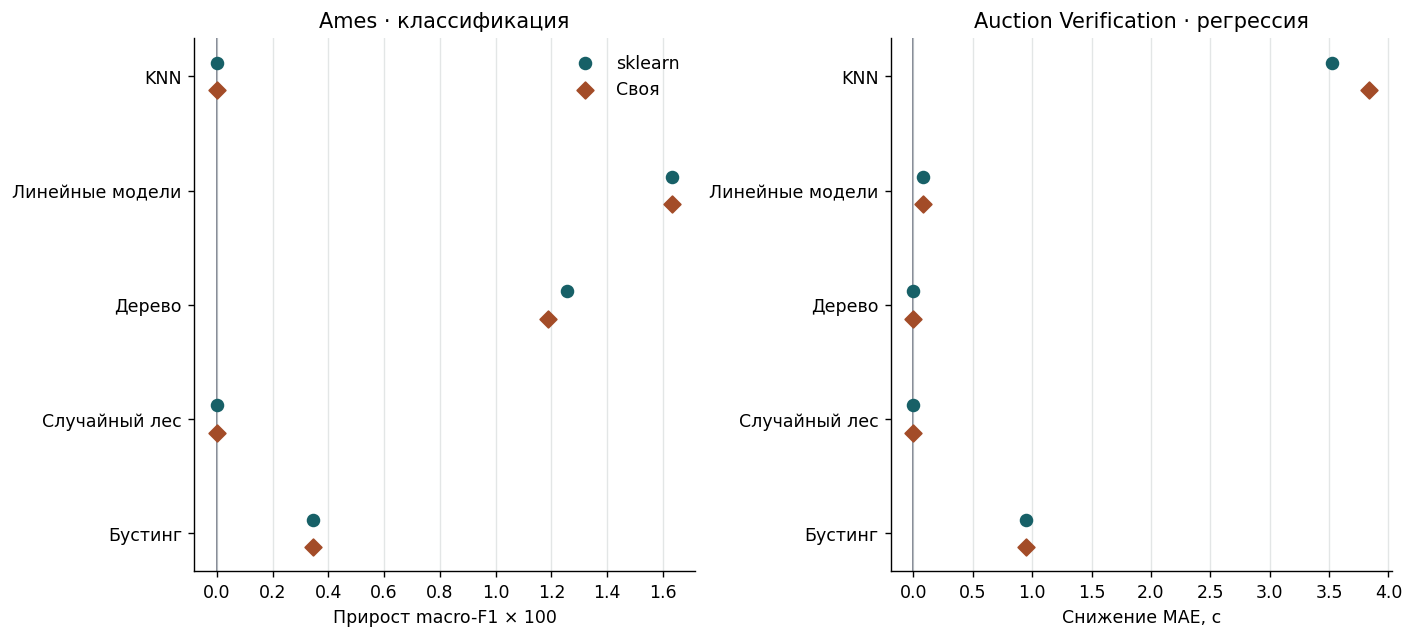

In [4]:
# Вычисляем парные разности на одинаковых тестовых объектах и строим две панели.
gains = {}
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5), layout="constrained")
for ax, (task, metric) in zip(axes, focus.items()):
    pairs = scores.loc[scores.task.eq(task)].pivot(
        index=["lab", "algorithm", "implementation"], columns="stage", values=metric
    )
    gain = (pairs["selected"] - pairs["base"]) * (100 if task == "classification" else -1)
    gains[task] = gain
    panel = gain.unstack("implementation").sort_index()
    ypos = np.arange(len(panel))
    ax.axvline(0, color="#6b7280", lw=1, zorder=0)
    for implementation, marker, offset, color in [
        ("sklearn", "o", -0.12, "#176067"), ("own", "D", 0.12, "#a34c28")
    ]:
        ax.scatter(panel[implementation], ypos + offset, s=46, marker=marker,
                   color=color, label=implementations[implementation], zorder=3)
    ax.set_yticks(ypos, panel.index.get_level_values("algorithm"))
    ax.invert_yaxis()
    ax.grid(axis="x", color="#d5d9da", alpha=0.65)
    ax.set_axisbelow(True)
    ax.set_title(task_titles[task])
    ax.set_xlabel("Прирост macro-F1 × 100" if task == "classification" else "Снижение MAE, с")
    ax.spines[["right", "top"]].set_visible(False)
axes[0].legend(loc="best", frameon=False)
image = BytesIO()
fig.savefig(image, format="png", dpi=125, bbox_inches="tight")
plt.close(fig)
display(Image(data=image.getvalue()))

## Лидеры и выводы

Найдём на тесте лучший результат отдельно для каждой реализации и стадии. Если несколько алгоритмов совпали с точностью до машинной погрешности, перечислим их вместе.

In [5]:
# Сравниваем значения до округления и сохраняем все ничьи.
ranking = []
for task, metric in focus.items():
    for implementation, label in implementations.items():
        for stage, stage_label in variants.items():
            subset = scores[
                scores.task.eq(task) & scores.implementation.eq(implementation) & scores.stage.eq(stage)
            ].sort_values("lab")
            best = subset[metric].max() if task == "classification" else subset[metric].min()
            tied = subset.loc[np.isclose(subset[metric], best, atol=1e-12, rtol=1e-12), "algorithm"]
            ranking.append([task_titles[task], label, stage_label, ", ".join(tied), best])
ranking = pd.DataFrame(ranking, columns=["Задача", "Реализация", "Стадия", "Алгоритм", "Основная метрика"])
display(ranking.set_index(["Задача", "Реализация", "Стадия"]).round(4))

Алгоритм  \
Задача                           Реализация Стадия                           
Ames · классификация             sklearn    Базовая          Случайный лес   
                                            Подобрана по CV  Случайный лес   
                                 Своя       Базовая          Случайный лес   
                                            Подобрана по CV  Случайный лес   
Auction Verification · регрессия sklearn    Базовая                 Дерево   
                                            Подобрана по CV         Дерево   
                                 Своя       Базовая          Случайный лес   
                                            Подобрана по CV  Случайный лес   

                                                             Основная метрика  
Задача                           Реализация Стадия                             
Ames · классификация             sklearn    Базовая                    0.9439  
                                            Подобрана по CV            0.9439  
                                 Своя       Базовая                    0.9473  
                                            Подобрана по CV            0.9473  
Auction Verification · регрессия sklearn    Базовая                    0.4846  
                                            Подобрана по CV            0.4846  
                                 Своя       Базовая                    0.4598  
                                            Подобрана по CV            0.4598

In [6]:
# Выделяем изменение качества и максимальный разрыв между реализациями.
for task, metric in focus.items():
    block = scores.loc[scores.task.eq(task) & scores.stage.eq("selected")]
    best = block[metric].max() if task == "classification" else block[metric].min()
    tied = block.loc[np.isclose(block[metric], best, atol=1e-12, rtol=1e-12)]
    best_models = ", ".join(
        f"{row.algorithm} ({implementations[row.implementation]})" for row in tied.itertuples()
    )
    gain = gains[task]
    improved, reduced = int((gain > 1e-10).sum()), int((gain < -1e-10).sum())
    same = len(gain) - improved - reduced
    side = block.pivot(index=["lab", "algorithm"], columns="implementation", values=metric)
    gaps = side["own"] - side["sklearn"]
    worst_gap = gaps.abs().max()
    max_gap_rows = gaps[np.isclose(gaps.abs(), worst_gap, atol=1e-12, rtol=1e-12)]
    metric_name = "macro-F1" if task == "classification" else "MAE (с)"
    if worst_gap < 1e-12:
        gap_note = "У всех пяти алгоритмов основные метрики двух реализаций совпали с машинной точностью."
    else:
        names = ", ".join(max_gap_rows.index.get_level_values("algorithm"))
        gap_note = f"Наибольшая абсолютная разница между реализациями после подбора — {worst_gap:.4f} по {metric_name} ({names})."
    display(Markdown(
        f"**{task_titles[task]}.** Лучшее значение {metric_name} среди подобранных конфигураций — "
        f"**{best:.4f}** ({best_models}). Из десяти пар «алгоритм — реализация» "
        f"на тесте улучшились {improved}, ухудшились {reduced}, сохранили результат {same}. {gap_note}"
    ))

**Ames · классификация.** Лучшее значение macro-F1 среди подобранных конфигураций — **0.9473** (Случайный лес (Своя)). Из десяти пар «алгоритм — реализация» на тесте улучшились 6, ухудшились 0, сохранили результат 4. Наибольшая абсолютная разница между реализациями после подбора — 0.0034 по macro-F1 (Дерево).

**Auction Verification · регрессия.** Лучшее значение MAE (с) среди подобранных конфигураций — **0.4598** (Случайный лес (Своя)). Из десяти пар «алгоритм — реализация» на тесте улучшились 6, ухудшились 0, сохранили результат 4. Наибольшая абсолютная разница между реализациями после подбора — 0.0303 по MAE (с) (Случайный лес).

Auction Verification содержит 2 043 наблюдения и 24 конфигурации лимитов участников. Модели обучались на 1 723 наблюдениях из 19 конфигураций. Кросс-валидация также проводилась по группам. Тест включает **320 наблюдений из пяти других конфигураций**. Несколько длительных проверок с крупной ошибкой могут изменить порядок моделей по RMSE. Тестовый рейтинг описывает это разбиение. Все решения о настройках опираются на обучающие фолды.